# TASK I

In [87]:
#Libraries
import re
import sys

#Data handling
import pandas as pd
import numpy as np

#Visualization
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
%matplotlib inline
import matplotlib.pyplot as plt

#Deep Learning
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

#Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import ComplementNB
from sklearn.utils.class_weight import compute_class_weight
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, precision_recall_fscore_support, f1_score
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

print(sys.executable)


/usr/bin/python3


### Figures, Tables and Graphs

In [98]:
df = pd.read_csv("reviews.csv")

df["rating"] = pd.to_numeric(df["rating"], errors="coerce")
df["helpful"] = pd.to_numeric(df["helpful"], errors="coerce").fillna(0).astype(int)

#Both mm/dd and dd/mm in the 'reviews.csv'
d1 = pd.to_datetime(df["review_date"], errors="coerce", dayfirst=False)
d2 = pd.to_datetime(df["review_date"], errors="coerce", dayfirst=True)
df["review_date"] = d1.fillna(d2)

df.head()

/tmp/ipykernel_2507/3038383825.py:8: UserWarning:

Parsing dates in %m/%d/%Y %H:%M format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.



,review_id,rating,review_text,review_date,helpful
0,981e465b-d3ba-4632-9c60-25051efac38a,5,It's good,2025-11-22 01:19:00,0
1,964d3555-9429-4c20-8127-ce3c71ce9273,5,WhatsApp not working well always shows offline...,2025-11-24 20:03:00,0
2,6c28859f-1554-4ca1-9aa8-9d66f204be0a,5,"Oppo not corresponding, share with me the offi...",2025-11-25 06:26:00,0
3,a7efafc3-5871-4020-a398-9cc12cb4072a,5,"Excellent app, great communication super conne...",2025-11-25 18:09:00,0
4,de142b31-a5ad-446f-b7c8-51b264728478,4,simply the ɓest for chat and calls.i love it,2025-11-24 01:10:00,1


In [99]:
fig = px.histogram(df, x="rating", nbins=5, title="Fordeling av rating")
fig.show() #About 50% of the dataset has 5 in rating

#### Top 20 Reviews Based on Helpful-votes

In [100]:
top_20_helpful = df.nlargest(20, 'helpful')[['rating', 'review_text', 'helpful']]
print(top_20_helpful)

      rating                                        review_text  helpful
4677       5  You are rolling out the reactions to messages ...   248962
1629       5  Please add an "edit status" feature.Also let's...     8696
5195       5  “I want WhatsApp to release an update in which...     4345
813        5  it's the Best messaging app I've used... it's ...     1884
4642       1  There is a major bug and privacy flaw where mu...     1688
4072       1        where is the scroll option for contact list      305
3115       2  5-star rating! WhatsApp is perfect for staying...      191
4082       3  I've noticed that when I start a new chat with...      188
6082       1  Many New features like Account Centre, Add Fac...      121
723        4  Love the app. But there's one bug that's been ...      113
2933       5  Can you add a feature to choose who can OPEN O...      101
703        2  good night i was using WhatsApp and I was bann...       95
4617       1  the about section character limit is 

In [101]:

# Predicts amount of words
df['word_count'] = df['review_text'].str.split().str.len()

# Removes extreme outliers for better visualization
word_count_99 = df['word_count'].quantile(0.99)
helpful_99 = df['helpful'].quantile(0.99)

df_visual = df[(df['word_count'] <= word_count_99) & (df['helpful'] <= helpful_99)]

# Splits word amount into groups
df_visual['word_group'] = pd.cut(df_visual['word_count'],
                                 bins=[0, 10, 20, 30, 50, 75, 100, 200, 500],
                                 labels=['0-10', '11-20', '21-30', '31-50', '51-75', '76-100', '101-200', '201+'])

# predicts average helpful votes per group
avg_helpful_by_words = df_visual.groupby('word_group', observed=True)['helpful'].mean().reset_index()

fig = px.bar(avg_helpful_by_words, x='word_group', y='helpful',
             title='Average helpful score based on wordcount',
             labels={'word_group': 'Number of words in the review',
                    'helpful': 'Average helpful votes'})
fig.update_yaxes(range=[0, avg_helpful_by_words['helpful'].max() * 1.1])  # Limits the y-axis
fig.show()

print(avg_helpful_by_words)

/tmp/ipykernel_2507/2979568348.py:11: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



  word_group   helpful
0       0-10  0.174670
1      11-20  0.279919
2      21-30  0.322981
3      31-50  0.580220
4      51-75  0.810484
5     76-100  1.109375


##### Starting the EDA, we manually looked at different reviews in the "reviews.csv" dataset to identify patterns that were either uninformative or noisy. We found several repeating patterns that we wanted to filter out. We made detect_unwanted_reviews() which marks a review as invalid if it met any of the criteria.


##### Too short review (<= 3 words) is one of them. Short reviews like ‘’I like’’ and ‘’good’’ provide minimal signal. The sentiment may seem clear, but the rating can be unpredictable, making it poor training data.

##### Too long words are another criterion. Reviews like "aHU4DCtH2mD9rhBxdZwXPAkfhASrXQTvktLUq3hSNkcd0EMIQVfZqEE8zL4ORd45u4k7uOiOXMxnyY0tnN8lBQBSMh4gh" appears as random gibberish and gives no value to the training.

##### Few stopwords in a longer review (>10 words) is a criterion, such as: ‘’ bike recommend competition agency hearing…’’. Stopwords (e.g., ‘’I’’, ‘’is’’, ‘’the’’, ‘’you’’) are essential for flow and grammar in a sentence (Shishiradhikari, 2025). With this in mind, we made a list with many of the most used stopwords. We then checked if reviews longer than ten words at least contained 8% stopwords.

##### Lastly, reviews containing repetitive words, such as: ‘’good good good good’’. These reviews contain no meaningful information and are looked at as noise.


### Data Filtering

In [ ]:


def detect_unwanted_reviews(text):
    if pd.isna(text):
        return {
            'is_valid': False,
            'reason': 'missing_text'}

    if text == '':
        return {
            'is_valid': False,
            'reason': 'No_text'}

    words = text.lower().split()
    word_count = len(words)

    #remove short reviews (3 or less words)
    if word_count <= 3:
        return {
            'is_valid': False,
            'reason': 'too_short'}

    #remove reviews containing the same number or word repetably (like '11111' or 'AAAAAA')
    text_without_space = re.sub(r'\s+', '',text)

    if len(text_without_space) >= 6:
        first_char = text_without_space[0]
        if all(c == first_char for c in text_without_space):
            return {
                'is_valid': False,
                'reason': 'repeating_characters'}

    #remove stings that are composed of random characters
    #like OZuZ05JvIrZcCzO8od8Qiogl3laDXMpBleqVst8K7 and swVXBcgpFzj0SCXRubdnhq7jiM0zO
    for word in words:
        if len(word) >= 20:
            return {
                'is_valid': False,
                'reason': 'too_long_word'}

    #remove the reviews that contains only one word which is repeated multiple times
    if word_count > 3:
        first_word = words[0]
        if all(w == first_word for w in words):
            return {
                'is_valid': False,
                'reason': 'repetetive_words'}

    stopwords = {'the', 'and', 'is', 'in', 'to', 'of', 'for', 'on', 'with',
             'this', 'that', 'it', 'was', 'are', 'as', 'at', 'be', 'have',
             'from', 'or', 'by', 'not', 'but', 'what', 'all', 'when', 'I', 'you'}

    stopword_count = sum(1 for w in words if w in stopwords)
    stopword_ratio = stopword_count/word_count if word_count > 0 else 0

    if word_count > 10 and stopword_ratio < 0.08:
        return {
            'is_valid': False,
            'reason': 'few_stopwords'}

    return {
        'is_valid': True,
        'reason': 'valid_review'}
print()
print('Original dataset')
print()
print('Total amount of reviews: ',len(df))

df['detection_result'] = df['review_text'].apply(detect_unwanted_reviews)
df['is_valid'] = df['detection_result'].apply(lambda x: x['is_valid'])
df['filter_reason'] = df['detection_result'].apply(lambda x: x['reason'])

df_cleaned = df[df['is_valid']== True].copy()

print()
print('After filtering')
print()
print('Original amount of reviews: ', len(df))
print('Removed: ',len(df)- len(df_cleaned))
print('Amount of valid reviews: ', len(df_cleaned))
print('Reduction: ', round((len(df) - len(df_cleaned))/len(df)*100,1),'%')
print()
print('Reason for removal:')
print(df[~df['is_valid']]['filter_reason'].value_counts())



Original dataset

Total amount of reviews:  6210

After filtering

Original amount of reviews:  6210
Removed:  2019
Amount of valid reviews:  4191
Reduction:  32.5 %

Reason for removal:
filter_reason
too_short           1543
few_stopwords        278
repetetive_words     177
too_long_word         21
Name: count, dtype: int64


##### After applying all filters, 2019 of the 6210 reviews (32.5%) were removed. The most dominant reason for removal was the too short reviews (76.4%). The second most popular reason was the few stopwords reviews (13.8%), followed by reviews containing repetitive words (8.8%) and lastly too long word reviews (1.0%).

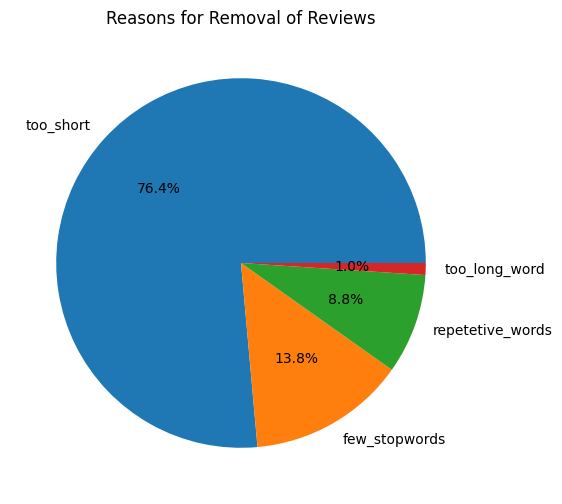

In [ ]:

removal_reasons = df[~df['is_valid']]['filter_reason'].value_counts()

plt.figure(figsize=(8, 6))
plt.pie(removal_reasons.values, labels=removal_reasons.index, autopct='%1.1f%%')
plt.title('Reasons for Removal of Reviews')
plt.show()

##### The chart visualizes the sorting of the reasons for removal, marked with percentages on each of the reasons.

### Comparison before vs after filtering

#### Wordcount

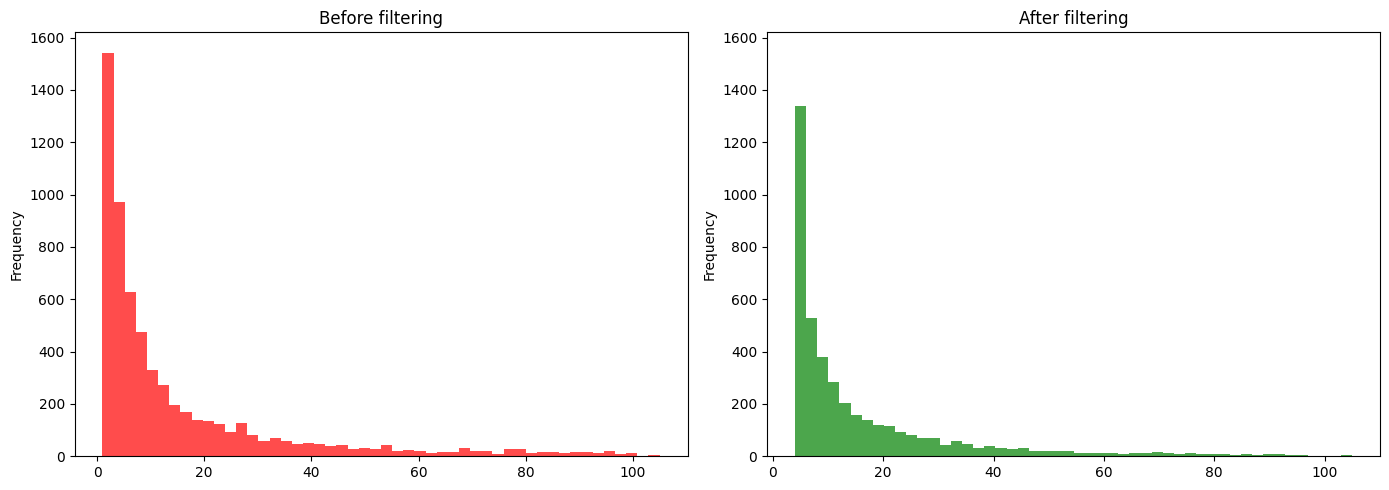

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

axes[0].hist(df['word_count'], bins=50, color='red', alpha=0.7)
axes[0].set_title('Before filtering')
axes[0].set_ylabel('Frequency')

axes[1].hist(df_cleaned['word_count'], bins=50, color='green', alpha=0.7)
axes[1].set_title('After filtering')
axes[1].set_ylabel('Frequency')

axes[1].tick_params(axis='y', labelleft=True)

plt.tight_layout()
plt.show()

#### Average reviewscore based on wordcount


/tmp/ipykernel_2507/3564488539.py:8: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.

/tmp/ipykernel_2507/3564488539.py:13: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



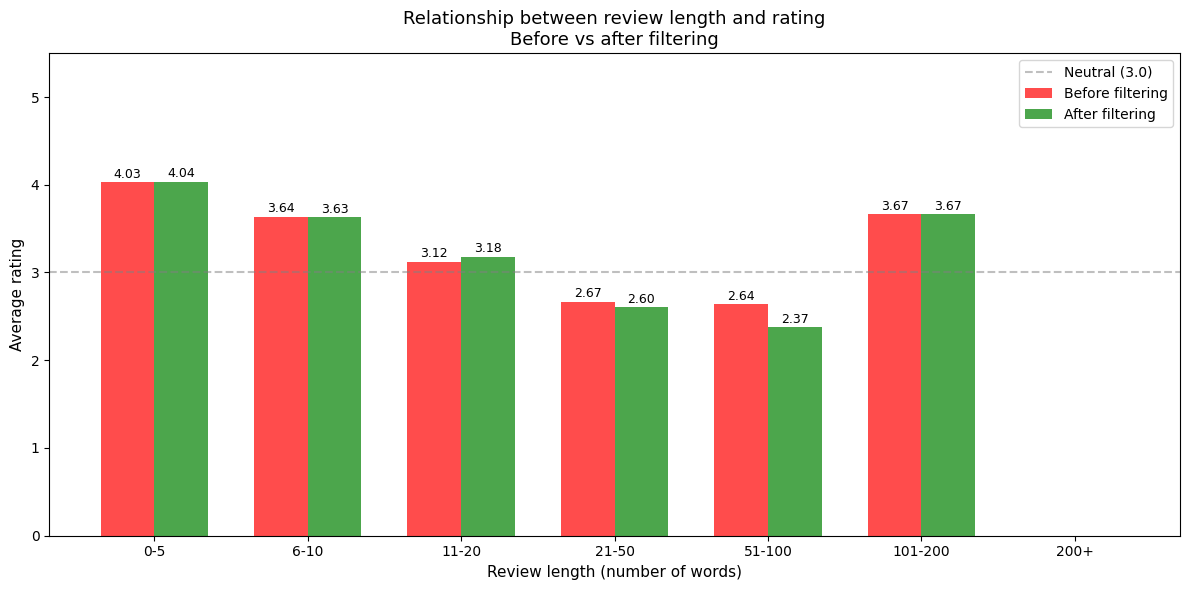

In [ ]:
# length groups
bins = [0, 5, 10, 20, 50, 100, 200, 500]
labels = ['0-5', '6-10', '11-20', '21-50', '51-100', '101-200', '200+']

# df
df['word_count'] = df['review_text'].apply(lambda x: len(str(x).split()))
df['length_group'] = pd.cut(df['word_count'], bins=bins, labels=labels, right=True)
avg_before = df.groupby('length_group')['rating'].mean()

#df_cleaned
df_cleaned['word_count'] = df_cleaned['review_text'].apply(lambda x: len(str(x).split()))
df_cleaned['length_group'] = pd.cut(df_cleaned['word_count'], bins=bins, labels=labels, right=True)
avg_after = df_cleaned.groupby('length_group')['rating'].mean()
avg_before = avg_before.reindex(labels)
avg_after = avg_after.reindex(labels)

# Fills NaN values with 0
avg_before = avg_before.fillna(0)
avg_after = avg_after.fillna(0)

# Bar chart
fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(len(labels))
width = 0.35

bars1 = ax.bar(x - width/2, avg_before.values, width, label='Before filtering', color='red', alpha=0.7)
bars2 = ax.bar(x + width/2, avg_after.values, width, label='After filtering', color='green', alpha=0.7)

# Value labels on bars
for bar in bars1:
    height = bar.get_height()
    if height > 0:
        ax.text(bar.get_x() + bar.get_width()/2, height + 0.05, f'{height:.2f}',
                ha='center', fontsize=9)

for bar in bars2:
    height = bar.get_height()
    if height > 0:
        ax.text(bar.get_x() + bar.get_width()/2, height + 0.05, f'{height:.2f}',
                ha='center', fontsize=9)

ax.set_xlabel('Review length (number of words)', fontsize=11)
ax.set_ylabel('Average rating', fontsize=11)
ax.set_title('Relationship between review length and rating\nBefore vs after filtering', fontsize=13)
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylim(0, 5.5)
ax.axhline(y=3.0, color='gray', linestyle='--', alpha=0.5, label='Neutral (3.0)')
ax.legend()

plt.tight_layout()
plt.show()

### Data Cleaning

In [ ]:
#datacleaning
def data_cleaning(text):
    text = str(text)
    text = text.lower()
    text = re.sub(r'http\S+|www\S+|https\S+', '', text)
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

stopwords = {'the', 'and', 'is', 'in', 'to', 'of', 'for', 'on', 'with',
             'this', 'that', 'it', 'was', 'are', 'as', 'at', 'be', 'have',
             'from', 'or', 'by', 'not', 'but', 'what', 'all', 'when', 'I', 'you'}

def remove_stopwords(text):
    words = text.split()
    words = [w for w in words if w not in stopwords]
    return ' '.join(words)

df_cleaned['clean_text'] = df_cleaned['review_text'].apply(data_cleaning)
df_cleaned['clean_text'] = df_cleaned['clean_text'].apply(remove_stopwords)

##### Before starting the data preparation, we cleaned the data in the reviews_text column. We converted the text to string to avoid any Valueerror. Then, made all the letters small, removed URL and links, kept only letters and spaces. With remove_stopwords(text), we removed stopwords in the reviews to leave the high valuated words left for the training.

### Data Preparation

In [ ]:
y = df_cleaned['rating']

X_train_text, X_test_text, y_train, y_test = train_test_split(
    df_cleaned['clean_text'], y, test_size=0.2, random_state=42, stratify=y
)

tfidf = TfidfVectorizer(max_features=5000)
X_train = tfidf.fit_transform(X_train_text)
X_test = tfidf.transform(X_test_text)

tokenizer = Tokenizer(num_words=5000)
tokenizer.fit_on_texts(X_train_text)

X_train_seq = tokenizer.texts_to_sequences(X_train_text)
X_test_seq = tokenizer.texts_to_sequences(X_test_text)

X_train_seq = pad_sequences(X_train_seq, maxlen=100, padding='post')
X_test_seq = pad_sequences(X_test_seq, maxlen=100, padding='post')

classes = np.array([1, 2, 3, 4, 5])
weights = compute_class_weight('balanced', classes=classes, y=y_train)
class_weights = dict(zip(classes, weights))
print("Class weights:", class_weights)

Class weights: {np.int64(1): np.float64(0.6585461689587426), np.int64(2): np.float64(3.0334841628959275), np.int64(3): np.float64(2.8286919831223627), np.int64(4): np.float64(2.36056338028169), np.int64(5): np.float64(0.421105527638191)}


##### The cleaned dataset is split into 80% training and 20% testing. We use stratify because the dataset is imbalanced with rating 5 dominating. With stratified splitting it will make sure the rating distribution is preserved in each set.

##### The text is converted to numbers in the traditional models, logistic regression, naive bayes and random forest, using TF-IDF. This will weigh the word based on how often they appear in the reviews. We set the limit to 5000 words to reduce dimensionality. To avoid data leaked, we only fit TF-IDF on the training data.

##### For the LSTM model we use tokenizer. The text is converted to sequences of numbers. Each review is either padded or truncated to 100 tokens, making them the same length. This is only trained on the training data.

##### Finaly, we weighted the classes, because of the imbalance of ratings. Rating 2, 3 and 4 receive a higher weight, than 1 and 5. This is used on the logistic regression model to make it pay more attention to the minority classes in training.


## Four Machine Learning Models

##### The models we chose for the task are Logistic Regression, Naïve Bayes, Random Forest and Long Short-Term Memory (LSTM). This is done by using sentiment analysis, with the task of figuring out whether a review is negative or positive based on the expressions in the texts (Müller & Guido, 2016, p. 325). To get a good linear baseline we started with Logistic Regression and Naïve Bayes models. Both are well suited due to them being fast and easy to interpret (Müller & Guido, 2016, p. 127). Random Forest on the other hand is a non-linear ensemble model that trains different trees before merging them together and giving a result based on the decision trees (Géron, 2019, p. 173). Long Short-Term Memory is an even more complex deep learning method designed for sequential data (Hochreiter & Schmidhuber, 1997). Due to the sequential data the LSTM model can recognise the order of the words, which separates it from the other three models. Having four different models grants us the opportunity to review how different methods deliver different or similar results.



### Logistic Regression

Accuracy: 0.501

Classification Report:
              precision    recall  f1-score   support

           1       0.57      0.55      0.56       255
           2       0.13      0.22      0.16        55
           3       0.07      0.12      0.09        60
           4       0.18      0.24      0.20        71
           5       0.79      0.61      0.69       398

    accuracy                           0.50       839
   macro avg       0.35      0.35      0.34       839
weighted avg       0.58      0.50      0.53       839



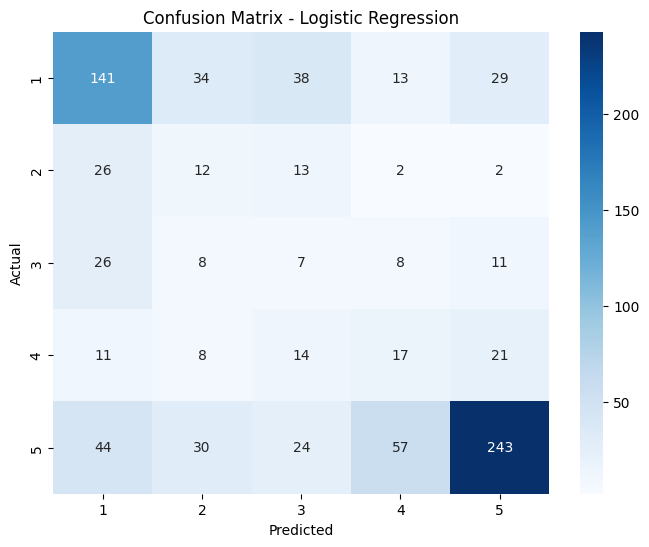


Examples of predictions (first 10):
   actual  predicted
0       1          2
1       5          3
2       5          5
3       5          5
4       1          1
5       1          5
6       2          3
7       5          5
8       2          2
9       1          1


In [ ]:
model_lr = LogisticRegression(max_iter=1000, random_state=42, class_weight=class_weights)
model_lr.fit(X_train, y_train)

y_pred_lr = model_lr.predict(X_test)

accuracy = accuracy_score(y_test, y_pred_lr)
print(f"Accuracy: {accuracy:.3f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

# Confusion matrix heatmap - Shows how the results are divide across the scale
cm = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=sorted(y.unique()),
            yticklabels=sorted(y.unique()))
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

results = pd.DataFrame({
    "actual": y_test.values,
    "predicted": y_pred_lr
})
print("\nExamples of predictions (first 10):")
print(results.head(10))

##### A Logistic Regression model adds up negative and positive words to create an overall polarity. Linear models like Logistic Regression are well suited for the type of text data we see in the reviews.csv dataset (Müller & Guido, 2016, p. 332). To limit the risk of overfitting we kept the L2 regularization with the default parameter C=1.0, which ensures the coefficients don’t get too large (Géron, 2019, p. 27). To ensure the model converges on the input we used max_iter=1000. In turn this prevents the model from memorizing the training data. To further balance the data, we used class_weight=class_weights, which shifts more focus to classes 2, 3, and 4. Despite this, the imbalance of the data limits the predicted classes to 1 and 5, with an accuracy of 64%.

### Naive Bayes

Accuracy: 0.6257449344457687
              precision    recall  f1-score   support

           1       0.53      0.80      0.64       255
           2       0.31      0.07      0.12        55
           3       0.25      0.05      0.08        60
           4       0.00      0.00      0.00        71
           5       0.76      0.79      0.77       398

    accuracy                           0.63       839
   macro avg       0.37      0.34      0.32       839
weighted avg       0.56      0.63      0.57       839



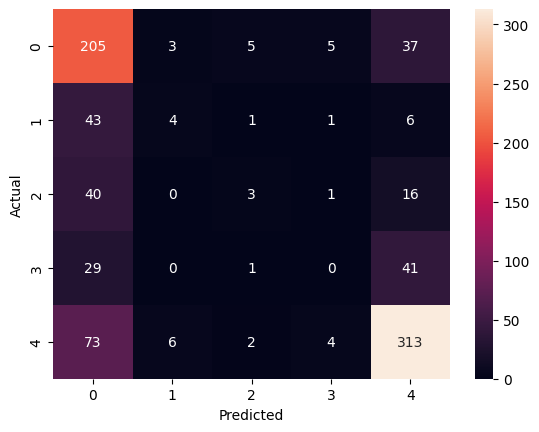

   actual  predicted
0       1          5
1       5          5
2       5          5
3       5          5
4       1          1
5       1          5
6       2          5
7       5          5
8       2          1
9       1          1


In [ ]:
model_nb = ComplementNB()
model_nb.fit(X_train, y_train)

y_pred_nb = model_nb.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_nb))
print(classification_report(y_test, y_pred_nb))

cm = confusion_matrix(y_test, y_pred_nb)

sns.heatmap(cm, annot=True, fmt="d")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

results = pd.DataFrame({
    "actual": y_test.values,
    "predicted": y_pred_nb
})

print(results.head(10))

##### In the Naive Bayes model we used ComplementNB instead of MultinomialNB. MultinomialNB tends to favor the majority classes when the dataset is imbalanced (Rennie et al., 2003). ComplementNB produces more stable parameter estimates by computing statistics on the complement of each class (scikit-learn Developers, n.d.;Rennie et al., 2003). This is a more suitable option for the dataset we’re working with.

##### The model achieved an accuracy of ~63%. In the classification report we can see that the model performs well on rating 1 and 5, with an F1-score of 0.64 and 0.77. On the ratings 2 – 4 it performs poorly. The confusion matrix shows that the model predicts wrong on the majority classes. This confirms the model struggles to predict the minority classes because of low training examples (Müller & Guido, 2016, p. 287).



### Random Forest

In [ ]:
model_rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=30,
    random_state=42,
    n_jobs=-1
)

model_rf.fit(X_train, y_train)

y_pred_rf = model_rf.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf))
print(confusion_matrix(y_test, y_pred_rf))

feature_names = tfidf.get_feature_names_out()
importances = model_rf.feature_importances_

indices = np.argsort(importances)[-10:]

print("The ten most important words: ")
for i in indices:
    print(feature_names[i], importances[i])

Accuracy: 0.6293206197854588
              precision    recall  f1-score   support

           1       0.59      0.62      0.61       255
           2       0.00      0.00      0.00        55
           3       0.00      0.00      0.00        60
           4       0.00      0.00      0.00        71
           5       0.65      0.93      0.76       398

    accuracy                           0.63       839
   macro avg       0.25      0.31      0.27       839
weighted avg       0.49      0.63      0.55       839

[[157   0   0   0  98]
 [ 34   0   0   0  21]
 [ 28   0   0   0  32]
 [ 18   0   0   0  53]
 [ 27   0   0   0 371]]
The ten most important words: 
its 0.010523200538150992
best 0.011463345920134876
nice 0.011917585855425445
whatsapp 0.012717345376485483
cant 0.013545709060210106
love 0.014308389253068264
very 0.014796562156626591
my 0.0170076832056172
good 0.024434108196511723
app 0.029365819392644054


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.



##### A Random Forest model creates a more robust classifier by combining different trained decision trees (Géron, 2019, p. 197). To gather more similar results and stable predictions we set the n_estimators=200 instead of a lower number, because higher numbers cause smoother boundaries (Müller & Guido, 2016, pp. 84-85). To further reduce the danger of overfitting the model we set the parameter of max_depth=30 while allowing the trees to model the word interactions. Despite these measures the model only achieves a 63% accuracy with predictions almost solely in classes 1 and 5. This matches what Müller and Guido state about Random Forest performing poorly on high-dimensional sparse text data (Müller & Guido, 2016, p. 128). The algorithm detects the most prominent and important words, such as “love”, “good”, and “best”. These words align well with positive sentiment aspects.

### Long Short-Term Memory (LSTM)

In [ ]:
y_train_binary = y_train.apply(lambda x: 1 if x >= 4 else 0)
y_test_binary = y_test.apply(lambda x: 1 if x >= 4 else 0)

cw = compute_class_weight('balanced', classes= np.array([0, 1]), y = y_train_binary.values)
classes_weight_dict = {0: cw[0], 1: cw[1]}

model_lstm = Sequential()
model_lstm.add(Embedding(input_dim=5000, output_dim=64, mask_zero=True))
model_lstm.add(LSTM(64, use_cudnn=False)) # Added use_cudnn=False to resolve the error
model_lstm.add(Dense(1, activation='sigmoid'))

model_lstm.compile(
    loss='binary_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

history = model_lstm.fit(X_train_seq, y_train_binary, epochs=10, batch_size=32, validation_split=0.2, class_weight=classes_weight_dict)

loss, acc = model_lstm.evaluate(X_test_seq, y_test_binary)
print("Accuracy:", acc)

#LSTM class predictions (0/1) from the sigmoid probabilities
lstm_probs = model_lstm.predict(X_test_seq).flatten()
y_pred_lstm_binary = (lstm_probs >= 0.5).astype(int)

Epoch 1/10
84/84 ━━━━━━━━━━━━━━━━━━━━ 17s 85ms/step - accuracy: 0.6721 - loss: 0.6163 - val_accuracy: 0.7571 - val_loss: 0.5431
Epoch 2/10
84/84 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 0.8150 - loss: 0.4472 - val_accuracy: 0.7660 - val_loss: 0.4938
Epoch 3/10
84/84 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.8706 - loss: 0.3438 - val_accuracy: 0.7765 - val_loss: 0.5208
Epoch 4/10
84/84 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.8985 - loss: 0.2768 - val_accuracy: 0.7571 - val_loss: 0.6336
Epoch 5/10
84/84 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.9187 - loss: 0.2224 - val_accuracy: 0.7601 - val_loss: 0.6375
Epoch 6/10
84/84 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.9280 - loss: 0.1918 - val_accuracy: 0.7288 - val_loss: 0.7403
Epoch 7/10
84/84 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.9396 - loss: 0.1667 - val_accuracy: 0.7183 - val_loss: 0.7568
Epoch 8/10
84/84 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.9388 - loss: 0.1603 - val_accuracy: 0.7139 - 

In [ ]:
hist = history.history
epochs = list(range(1, len(hist['loss']) + 1))

fig = make_subplots(rows=1, cols=2, subplot_titles=('Loss', 'Accuracy'))

fig.add_trace(go.Scatter(x=epochs, y=hist['loss'],
                         mode='lines+markers', name='Train loss'),
              row=1, col=1)
fig.add_trace(go.Scatter(x=epochs, y=hist['val_loss'],
                         mode='lines+markers', name='Val loss'),
              row=1, col=1)
fig.add_trace(go.Scatter(x=epochs, y=hist['accuracy'],
                         mode='lines+markers', name='Train acc'),
              row=1, col=2)
fig.add_trace(go.Scatter(x=epochs, y=hist['val_accuracy'],
                         mode='lines+markers', name='Val acc'),
              row=1, col=2)

fig.update_xaxes(title_text='Epoch')
fig.update_layout(
    title_text='LSTM training dynamics',
    template='plotly_white', height=400,
)
fig.show()

##### We converted to binary classification (positive: >=4, negative: 1-3) in the LSTM due to class imbalance and computational constraints. The architecture of the model includes an embedding layer (64 dimensions), LSTM layer (64 units) and a sigmoid output layer with class weights.

##### The model achieved 73.7% accuracy. The training log shows clear overfitting after epoch 3. The accuracy peaked at epoch 1 (79%), but steadily reduced to 71% in epoch 10, while training accuracy rose to 95%. The final gap was at 24%, indicating large overfitting. With the use of early stopping after epoch 2, the model would have generalized better. Adding dropout regularization could have also helped.


## Summary and comparison

In [ ]:
# Convert the other models' multiclass predictions to binary (rating >= 4)
def to_binary(arr):
    return (np.asarray(arr) >= 4).astype(int)

y_test_binary_arr = to_binary(y_test)
y_pred_lr_binary  = to_binary(y_pred_lr)
y_pred_nb_binary  = to_binary(y_pred_nb)
y_pred_rf_binary  = to_binary(y_pred_rf)

# Group predictions for easier iteration
models_multiclass = {
    'Logistic Regression': y_pred_lr,
    'Naive Bayes':         y_pred_nb,
    'Random Forest':       y_pred_rf,
}

models_binary = {
    'Logistic Regression': y_pred_lr_binary,
    'Naive Bayes':         y_pred_nb_binary,
    'Random Forest':       y_pred_rf_binary,
    'LSTM':                y_pred_lstm_binary,
}


summary_rows = []
for name, preds in models_binary.items():
    p, r, f, _ = precision_recall_fscore_support(
        y_test_binary_arr, preds, average='weighted', zero_division=0
    )
    summary_rows.append({
        'Model': name,
        'Accuracy (binary)': round(accuracy_score(y_test_binary_arr, preds), 3),
        'Precision': round(p, 3),
        'Recall': round(r, 3),
        'F1': round(f, 3),
    })

summary_df = pd.DataFrame(summary_rows)
summary_df

,Model,Accuracy (binary),Precision,Recall,F1
0,Logistic Regression,0.766,0.777,0.766,0.767
1,Naive Bayes,0.789,0.795,0.789,0.790
2,Random Forest,0.766,0.778,0.766,0.759
3,LSTM,0.732,0.732,0.732,0.732


In [ ]:
rows = []
for name, preds in models_multiclass.items():
    rows.append({'Model': name, 'Task': 'Multiclass (1-5)',
                 'Accuracy': accuracy_score(y_test, preds)})
for name, preds in models_binary.items():
    rows.append({'Model': name, 'Task': 'Binary (>=4)',
                 'Accuracy': accuracy_score(y_test_binary_arr, preds)})

acc_df = pd.DataFrame(rows)

fig = px.bar(
    acc_df, x='Model', y='Accuracy', color='Task', barmode='group',
    text=acc_df['Accuracy'].map(lambda v: f'{v:.3f}'),
    title='Accuracy per model — multiclass vs binary task',
    color_discrete_sequence=['#636EFA', '#EF553B'],
)
fig.update_traces(textposition='outside')
fig.update_yaxes(range=[0, 1.05])
fig.update_layout(template='plotly_white', height=450)
fig.show()

In [ ]:
metric_rows = []
for name, preds in models_binary.items():
    p, r, f, _ = precision_recall_fscore_support(
        y_test_binary_arr, preds, average='weighted', zero_division=0
    )
    metric_rows.append({'Model': name, 'Metric': 'Precision', 'Score': p})
    metric_rows.append({'Model': name, 'Metric': 'Recall',    'Score': r})
    metric_rows.append({'Model': name, 'Metric': 'F1',        'Score': f})

metric_df = pd.DataFrame(metric_rows)

fig = px.bar(
    metric_df, x='Model', y='Score', color='Metric', barmode='group',
    text=metric_df['Score'].map(lambda v: f'{v:.3f}'),
    title='Precision / Recall / F1 (weighted) — binary task',
)
fig.update_traces(textposition='outside')
fig.update_yaxes(range=[0, 1.05])
fig.update_layout(template='plotly_white', height=450)
fig.show()

In [ ]:
classes = sorted(y_test.unique())
f1_matrix = []
for name, preds in models_multiclass.items():
    f1_per_class = f1_score(y_test, preds, labels=classes,
                            average=None, zero_division=0)
    f1_matrix.append(f1_per_class)

fig = go.Figure(data=go.Heatmap(
    z=f1_matrix,
    x=[f'Rating {c}' for c in classes],
    y=list(models_multiclass.keys()),
    colorscale='Blues',
    text=[[f'{v:.2f}' for v in row] for row in f1_matrix],
    texttemplate='%{text}',
    zmin=0, zmax=1,
    colorbar=dict(title='F1'),
))
fig.update_layout(
    title='Per-class F1 score — multiclass task',
    template='plotly_white', height=350,
)
fig.show()

In [ ]:
# Confusion matrixes
fig = make_subplots(
    rows=2, cols=2,
    subplot_titles=list(models_multiclass.keys()) + ['LSTM (binary)'],
    horizontal_spacing=0.15, vertical_spacing=0.18,
)

classes = sorted(y_test.unique())

positions = [(1, 1), (1, 2), (2, 1)]
for (name, preds), (r, c) in zip(models_multiclass.items(), positions):
    cm = confusion_matrix(y_test, preds, labels=classes)
    fig.add_trace(
        go.Heatmap(
            z=cm, x=[str(x) for x in classes], y=[str(x) for x in classes],
            colorscale='Blues', showscale=False,
            text=cm, texttemplate='%{text}',
        ),
        row=r, col=c,
    )

cm_lstm = confusion_matrix(y_test_binary_arr, y_pred_lstm_binary, labels=[0, 1])
fig.add_trace(
    go.Heatmap(
        z=cm_lstm, x=['Neg (0)', 'Pos (1)'], y=['Neg (0)', 'Pos (1)'],
        colorscale='Blues', showscale=False,
        text=cm_lstm, texttemplate='%{text}',
    ),
    row=2, col=2,
)

fig.update_xaxes(title_text='Predicted')
fig.update_yaxes(title_text='Actual', autorange='reversed')
fig.update_layout(
    title_text='Confusion matrixes — all four models',
    template='plotly_white', height=700, showlegend=False,
)
fig.show()

### Comparison
##### When training the traditional models (Logistic Regression, Naive Bayes, Random Forest) on the multiclass task, we found a clear pattern in the confusion matrixes. The models predict extreme ratings (1 and 5) most of the time, and rarely predicts 2, 3 and 4. Showing that the imbalanced data set causes the prediction of the minority classes to be infeasible, as models default to predict the majority classes instead.

##### When converted to binary classification, we saw that all the models performed at a higher level. This was expected since the models goes from having to predict the exact rating (1 – 5), to only 0/1(1-3 or >=4).

##### We use the F1-score for comparison, because it works well on imbalanced data and balances precision and recall (Sharma, 2023). Looking at the F1 score, Naive Bayes was the model that achieved the highest score (0.79), surpassing Logistic Regression (0.767) and Random Forest (0.76). The similarities between the results suggest that the main issue is the data imbalance not the choice of algorithm.

##### LSTM was the model that achieved the lowest score (0.737). As previously mentioned, the model is overfitted, which could have been improved by using early stopping by epoch 2 or adding dropout regularization.


### Summary
##### We made four machine learning models (Logistic Regression, Naive Bayes, Random Forest, LSTM) to predict review rating based on the review text. After filtering the dataset went from 6210 to 4191 reviews (32.5% reduction).

##### The main challenge was the imbalanced dataset, with rating 5 being over 70% of the review ratings. This is confirmed in the confusion matrixes to the models, where models struggle to predict minority classes (rating 2-4), defaulting to the majority classes (rating 1 and 5).

##### Using binary classification, the models performed a higher accuracy score. Naive Bayes achieved the highest F1-score (0.79), with Logistic Regression (0.767) and Random Forest (0.76) right beneath. Suggesting that algorithm choice matters less than addressing imbalance. LSTM showed overfitting after epoch 2, having a gap at 24% in epoch 10.

##### Conclusion, the data imbalance is the main challenge, not the choice of algorithms. Binary classification proved to be a more suited approach for this dataset.


Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow :
Concepts, Tools, and Techniques to Build Intelligent Systems:
- Confusion Matrix (Page 93)
- Overfitting data (Page 27)
- Underfitting data (Page 29)
- Logistic Regression (Page 142)
- Random Forest (Page 197)
Cite:
Géron, Aurélien. Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow : Concepts, Tools, and Techniques to Build Intelligent Systems, O'Reilly Media, Incorporated, 2019.
ProQuest Ebook Central, https://ebookcentral.proquest.com/lib/bergen-ebooks/detail.action?docID=5892320.



Hochreiter, S., & Schmidhuber, J. (1997). Long short-term memory. Neural Computation, 9(8), 1735–1780. https://doi.org/10.1162/neco.1997.9.8.1735

Müller, Andreas C., og Sarah Guido. Introduction to Machine Learning with Python: A Guide for Data Scientists. O'Reilly Media, 2016.


Rennie, J. D., Shih, L., Teevan, J., & Karger, D. R. (2003).
Tackling the poor assumptions of naive Bayes text classifiers. In ICML (Vol. 3, pp. 616-623). https://people.csail.mit.edu/jrennie/papers/icml03-nb.pdf

Anthropic. (2026). https://claude.ai

DeepSeek. (2026). https://www.deepseek.com

Scikit-learn Developers. (n.d.). ComplementNB – scikit-learn 1.7.2 documentation. GitHub. Retrieved from  https://github.com/scikit-learn/scikit-learn/blob/fe2edb3cd/sklearn/naive_bayes.py#L939

Sharma, N. (2023, June 10). Understanding and Applying F1 Score: AI Evaluation Essentials with Hands-On Coding Example. Arize AI. https://arize.com/blog-course/f1-score/

Shrestha, S. (2025, June 9). A simple understanding of stopwords in NLP. Medium. https://medium.com/@shishiradhikari444/a-simple-understanding-of-stopwords-in-nlp-dd24e36fd228

# TASK II

In [4]:
import PIL
from PIL import Image
from google.colab import drive, files
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, random_split, Subset, WeightedRandomSampler, TensorDataset
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, roc_auc_score, roc_curve, f1_score)
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
from torch.amp import autocast, GradScaler
from collections import Counter
import random
import warnings
import os
import time
import shutil

In [5]:
drive.mount('/content/drive')
#mounting google drive

Mounted at /content/drive


In [71]:
if not os.path.exists('/content/Art_shuffled'):
    shutil.copytree('/content/drive/MyDrive/Art_shuffled', '/content/Art_shuffled')
    print("Ferdig kopiert!")
else:
    print("Allerede lokalt!")


Allerede lokalt!


###1. Project Overview

The objective of this project is to develop a binary classifier capable of distinguishing between AI-generated images and human-created artwork. By leveraging Transfer Learning with a pre-trained ResNet-18 model, we aim to achieve high accuracy despite a relatively small specialized dataset.

### 2. Dataset Characteristics

The dataset is composed of 951 total images, categorized as follows:
AI-Generated (Class 0): 526 images
Human-Made (Class 1): 425 images

###3. Class Imbalance Handling

To prevent the model from developing a bias toward the majority class (AI), we implement a WeightedRandomSampler. This ensures that every training batch has an equal probability of presenting AI and human-made art, providing a more balanced learning signal.

### 4. Technical Implementation

Reading images from Google Drive is slow. To solve this, we copy the data to the local environment and load the entire dataset into system RAM as tensors. This reduces training time significantly.

###5. Training Strategy

Phase 1: Train only the classification head while the ResNet backbone remains frozen.
Phase 2: Unfreeze the deeper layers (layer4) and use a lower learning rate to recognize fine-grained artifacts unique to AI art.

In [76]:
# Had trouble with the PIL warning system,
# due to it detecting files before they were transformed into their proper shape and colour
warnings.filterwarnings('ignore', category=UserWarning, module='PIL')

torch.manual_seed(42)
random.seed(42)

# Convert all images to RGB, resize to 224x224 (ResNet18 input size),
# and normalize using ImageNet mean and std since the model was pretrained on it
transform = transforms.Compose([
    transforms.Lambda(lambda img: img.convert('RGB')),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

dataset = datasets.ImageFolder(root='/content/Art_shuffled', transform=transform)

print(dataset.classes)
print(f"Total images: {len(dataset)}")
#korter opp datasettet for raskere trening
sample_size = int(1 * len(dataset))
indices = random.sample(range(len(dataset)), sample_size)
dataset = Subset(dataset, indices)

['AiArtData', 'RealArt']
Total images: 951


## Loading into ram

This is what makes our model run extremely efficiently. Loading all images into RAM eliminates repeated disk reads during training.
reducing training time from ~1 minute per epoch to a few seconds.

In [77]:
print("Loading pictures into ram")
all_images = []
all_labels = []

# Load the dataset into the RAM
full_loader = DataLoader(dataset, batch_size=32, num_workers=0)
for images, labels in full_loader:
    all_images.append(images)
    all_labels.append(labels)

all_images = torch.cat(all_images)
all_labels = torch.cat(all_labels)

print(f"Done, Shape: {all_images.shape}")

full_tensor_dataset = TensorDataset(all_images, all_labels)

# Initializing the training, valuation and test subsets
train_size = int(0.7 * len(full_tensor_dataset))
val_size = int(0.15 * len(full_tensor_dataset))
test_size = len(full_tensor_dataset) - train_size - val_size

train_set, val_set, test_set = random_split(full_tensor_dataset, [train_size, val_size, test_size])

Loading pictures into ram
Done, Shape: torch.Size([951, 3, 224, 224])


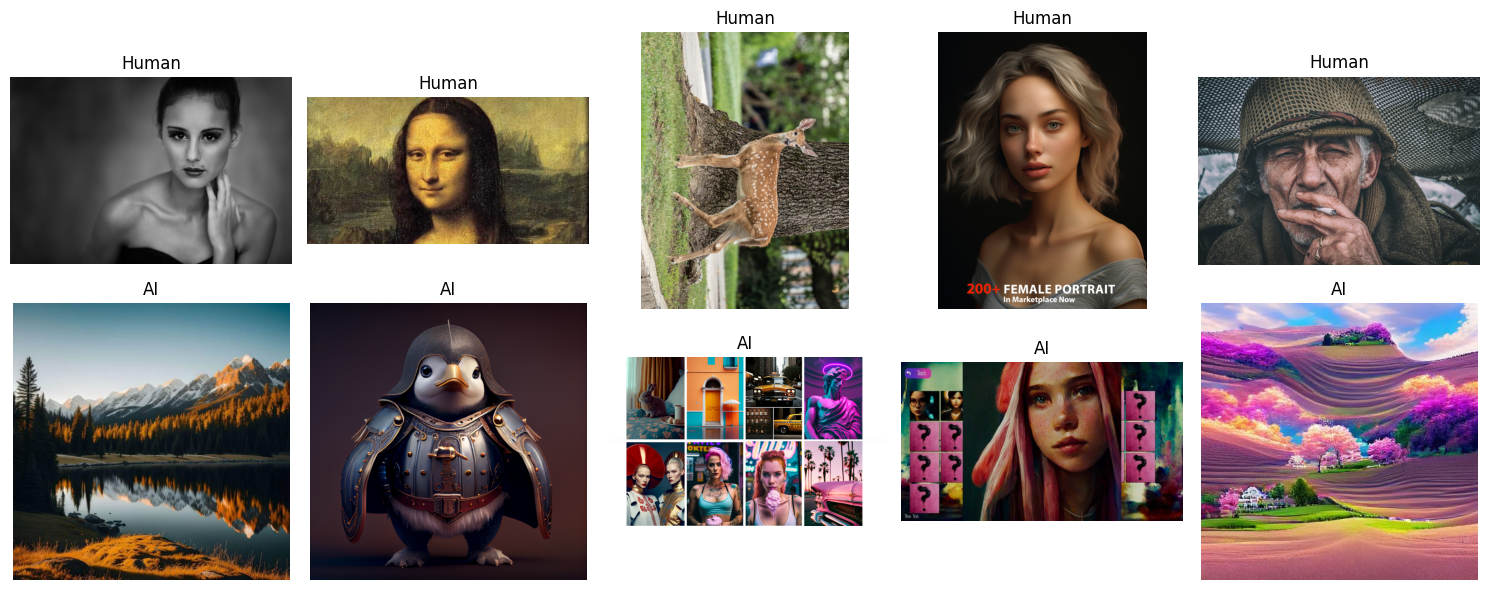

In [90]:
fig, axes = plt.subplots(2, 5, figsize=(15, 6))

# Vis 5 Human og 5 AI bilder fra datasettet
human_indices = [i for i, (_, l) in enumerate(dataset.dataset.samples) if l == 1][:5]
ai_indices = [i for i, (_, l) in enumerate(dataset.dataset.samples) if l == 0][:5]

for idx, i in enumerate(human_indices):
    img_path = dataset.dataset.samples[i][0]
    img = Image.open(img_path).convert('RGB')
    axes[0][idx].imshow(img)
    axes[0][idx].axis('off')
    axes[0][idx].set_title('Human')

for idx, i in enumerate(ai_indices):
    img_path = dataset.dataset.samples[i][0]
    img = Image.open(img_path).convert('RGB')
    axes[1][idx].imshow(img)
    axes[1][idx].axis('off')
    axes[1][idx].set_title('AI')

plt.tight_layout()
plt.show()

## EDA

EDA looks into the quality of the dataset. We believe that the 4th human photo is really ai. if this is a consistent problem the model will classify seemingly ai photos as human. Looking through the dataset we also see many instances of a comparison photo in the ai art section. These photos compare a human photo/art and an ai rendering of the same photo. This means that half of the photo is human art yet the model is made to believe the whole photo is ai. This can severely impact the models efficiency and will make the model bias towards ai photos.

##Unbalanced dataset

The dataset we are reviewing has approximately 100 more ai photos than human photos. It will then tend towards ai photos due to it being trained more on that style of photos. We counter this by adding WeightedRandomSampler. This sampler compensates by giving higher sampling probability to the minority class

In [78]:
# Get all labels for the training set only
train_labels = [full_tensor_dataset.tensors[1][i].item() for i in train_set.indices]
counts = Counter(train_labels)

# Calculate weights based on the actual training distribution
class_weights = {cls: len(train_labels) / count for cls, count in counts.items()}
sample_weights = [class_weights[label] for label in train_labels]

sampler = WeightedRandomSampler(weights=sample_weights, num_samples=len(sample_weights), replacement=True)

In [79]:
train_loader = DataLoader(train_set, batch_size=32, sampler=sampler, shuffle=False)
val_loader   = DataLoader(val_set, batch_size=32)
test_loader  = DataLoader(test_set, batch_size=32)

In [80]:
# Printing batches per epoch and photos in the training subset
print(f"Batches per epoch: {len(train_loader)}")
print(f"Total photos in training: {len(train_set)}")

Batches per epoch: 21
Total photos in training: 665


## Why ResNet-18?

The model selected for this task is ResNet-18, a convolutional neural network that has proven to be highly effective for image classification problems.

### 1. Good Balance Between Performance and Simplicity
ResNet-18 offers an excellent trade-off between accuracy and computational efficiency. While more complex models such as EfficientNet or deeper ResNet variants may achieve slightly higher performance, they require significantly more computational resources and longer training times. For this task, ResNet-18 provides reliable results without unnecessary complexity. As Géron notes, simpler models that generalize well are often preferable to more complex ones, particularly when data is limited [1].

### 2. Residual Connections Improve Training Stability
One of the key advantages of ResNet-18 is the use of residual (skip) connections, which help mitigate the vanishing gradient problem. This allows the network to train more effectively, even with limited data, ensuring stable convergence and better generalization. The vanishing gradient problem is a well-documented challenge in deep networks, where gradients shrink as they propagate backwards through layers, making learning increasingly difficult [1].

### 3. Suitable for Limited Datasets
The dataset used in this task is relatively small (951 images) compared to large-scale datasets like ImageNet. ResNet-18, especially when used with transfer learning, is well-suited for such scenarios. Chollet describes transfer learning as one of the most powerful techniques for working with small image datasets, where a pretrained model's learned feature representations are reused for a new classification task [2]. This means the model can leverage pre-learned visual features, reduce the risk of overfitting, and perform well with fewer training samples.


### 4. Ease of Implementation and Reproducibility
ResNet-18 is widely available in deep learning libraries such as PyTorch and TensorFlow, making it straightforward to implement. Its simplicity reduces the likelihood of implementation errors and makes the workflow more reproducible, which is particularly important in an academic setting. Géron emphasizes that reproducibility and transparency are essential qualities in applied machine learning work [1].

### Optimal Model Consideration
Although models like EfficientNet or Vision Transformers (ViT) may achieve higher accuracy — particularly for detecting subtle global inconsistencies in AI-generated images — they introduce additional complexity and computational cost that are not strictly necessary for this task given our resource constraints. ResNet-50 may also lead to longer training times without a proportional improvement in performance given our dataset size of only 951 images.

In conclusion, ResNet-18 is the most appropriate choice for this task because it combines solid performance, computational efficiency, and ease of use — characteristics that make it particularly well-suited for binary image classification with limited datasets and constrained resources.

---
**References**

[1] Géron, A. (2019). *Hands-On Machine Learning with Scikit-Learn, Keras & TensorFlow*. O'Reilly Media.

[2] Chollet, F. (2018). *Deep Learning with Python*. Manning Publications.
    Ch. 5.3: Using a pretrained convnet, pp. 143–159.

In [81]:

##
## Resetting the model between runs
##
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

model = models.resnet18(weights='IMAGENET1K_V1')
for param in model.parameters():
    param.requires_grad = False

# Adding dropout to avoid overfitting
model.fc = torch.nn.Sequential(
    torch.nn.Dropout(0.5),  # We saw alot of overfitting so we chose a high dropout of 50% of neurons
    torch.nn.Linear(512, 1)
).to(device)
#
model = model.to(device)

# Loading the best model from previous trainings
#model.load_state_dict(torch.load('/content/drive/MyDrive/best_model_ft.pth'))
print("Modell resatt!")

Using device: cuda
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 162MB/s]


Modell resatt!


## Training the model

When training the model we have several choices on how to do so. We chose to train it in two distinct phases, following the approach described by Chollet for fine-tuning pretrained convnets [2].

### Phase 1 — Training the classification head
In the first phase, all layers of the pretrained ResNet-18 are frozen except for the newly added classification head. This means only the final fully connected layer with dropout is updated during backpropagation. We do this for two reasons: first, to avoid disrupting the pretrained weights before the head has learned anything meaningful, and second, to reduce computational cost since far fewer parameters are being updated.

We use the Adam optimizer with a learning rate of 1e-3 and weight decay of 1e-2 to regularize the head. Binary Cross Entropy with Logits (BCEWithLogitsLoss) is used as the loss function, which is the standard choice for binary classification tasks as it combines a sigmoid activation and cross entropy loss in a numerically stable way.

### Phase 2 — Fine-tuning deeper layers
In the second phase, we unfreeze layer4 of ResNet-18 while keeping all earlier layers frozen. This allows the model to adapt the higher-level feature representations to our specific task of distinguishing AI-generated from human-made art. Layer3 remains frozen to limit the number of trainable parameters and reduce the risk of overfitting, which was a concern given our relatively small dataset of 951 images.


### Overfitting and regularization
Overfitting was observed during training, where training loss continued to fall while validation loss plateaued. To counter this we applied several techniques: dropout (0.5) in the classification head, weight decay in the optimizer, and saving only the best model checkpoint based on validation loss. The best model is loaded for evaluation rather than the final epoch, ensuring we evaluate the most generalizable version.

In [82]:

criterion = nn.BCEWithLogitsLoss()

# # Phase 1: only the classification head is trained
# This stabilizes the head before unfreezing deeper layers
optimizer = optim.Adam([
    {'params': model.fc.parameters(), 'lr': 1e-3,'weight_decay' : 1e-2}
])


scaler = GradScaler('cuda')

train_losses = []
val_losses = []
best_val_loss = float('inf')

for epoch in range(15):
    model.train()
    running_loss = 0
    for batch_idx, (images, labels) in enumerate(train_loader):
        images = images.to(device)
        labels = labels.float().unsqueeze(1).to(device)

        optimizer.zero_grad()

        # ↓ Mixed precision nå integrert i selve løkken
        with autocast('cuda'):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item()
        print(f"  Epoch {epoch+1} | Batch {batch_idx}/{len(train_loader)} | Loss: {loss.item():.4f}", end='\r')

    train_loss = running_loss / len(train_loader)
    train_losses.append(train_loss)

    model.eval()
    val_loss = 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.float().unsqueeze(1).to(device)
            val_loss += criterion(model(images), labels).item()

    val_loss = val_loss / len(val_loader)
    val_losses.append(val_loss)


# Save the best model based on validation loss to avoid saving an overfitted version

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), '/content/drive/MyDrive/best_model.pth')
        print(f"Epoch {epoch+1}/15 | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} ✓ Lagret!")
    else:
        print(f"Epoch {epoch+1}/15 | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")

Epoch 1/30 | Train Loss: 0.7509 | Val Loss: 0.5910 ✓ Lagret!
Epoch 2/30 | Train Loss: 0.6866 | Val Loss: 0.6808
Epoch 3/30 | Train Loss: 0.6340 | Val Loss: 0.5564 ✓ Lagret!
Epoch 4/30 | Train Loss: 0.6318 | Val Loss: 0.5213 ✓ Lagret!
Epoch 5/30 | Train Loss: 0.5727 | Val Loss: 0.5615
Epoch 6/30 | Train Loss: 0.5582 | Val Loss: 0.5097 ✓ Lagret!
Epoch 7/30 | Train Loss: 0.5739 | Val Loss: 0.5232
Epoch 8/30 | Train Loss: 0.5367 | Val Loss: 0.5333
Epoch 9/30 | Train Loss: 0.5158 | Val Loss: 0.5030 ✓ Lagret!
Epoch 10/30 | Train Loss: 0.5588 | Val Loss: 0.5694
Epoch 11/30 | Train Loss: 0.4964 | Val Loss: 0.5029 ✓ Lagret!
Epoch 12/30 | Train Loss: 0.5101 | Val Loss: 0.5472
Epoch 13/30 | Train Loss: 0.4948 | Val Loss: 0.5248
Epoch 14/30 | Train Loss: 0.5223 | Val Loss: 0.4981 ✓ Lagret!
Epoch 15/30 | Train Loss: 0.4961 | Val Loss: 0.5669


## Early stopping
We decided not to implement early stopping to the training so we can efficiently see how the model adapts
With the early stopping enabled we might get a slightly better model, but our goal is to not only get a good model but to see how it works and learns.
we do however save the best model so we can compare how they differ.

In [83]:
# Here we have unfreezed layer 4 but chosen to let layer 3 be frozen
# This is to avoid getting too many parameters and avoid overfitting.

for param in model.layer4.parameters():
    param.requires_grad = True
for param in model.layer3.parameters():
    param.requires_grad = False



optimizer = optim.Adam([
    {'params': model.layer4.parameters(), 'lr': 1e-5, 'weight_decay' : 1e-2},
    {'params': model.fc.parameters(), 'lr': 1e-4,'weight_decay' : 1e-2},
    {'params': model.layer3.parameters(), 'lr': 1e-5,'weight_decay':1e-3}
])


scaler = GradScaler('cuda')

train_losses_ft = []
val_losses_ft = []
best_val_loss_ft = float('inf')

for epoch in range(15):
    model.train()

    running_loss = 0
    for batch_idx, (images, labels) in enumerate(train_loader):
        images = images.to(device)
        labels = labels.float().unsqueeze(1).to(device)
        optimizer.zero_grad()
        with autocast('cuda'):
            outputs = model(images)
            loss = criterion(outputs, labels)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        running_loss += loss.item()
        print(f"  Epoch {epoch+1} | Batch {batch_idx}/{len(train_loader)} | Loss: {loss.item():.4f}", end='\r')

    train_loss = running_loss / len(train_loader)
    train_losses_ft.append(train_loss)

    model.eval()
    val_loss = 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.float().unsqueeze(1).to(device)
            val_loss += criterion(model(images), labels).item()
    val_loss = val_loss / len(val_loader)
    val_losses_ft.append(val_loss)


    if val_loss < best_val_loss_ft:
        best_val_loss_ft = val_loss
        torch.save(model.state_dict(), '/content/drive/MyDrive/best_model_ft.pth')
        print(f"Epoch {epoch+1}/15 | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} ✓ Lagret!")
    else:
        print(f"Epoch {epoch+1}/15 | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")


Epoch 1/15 | Train Loss: 0.4690 | Val Loss: 0.5279 ✓ Lagret!
Epoch 2/15 | Train Loss: 0.4502 | Val Loss: 0.4973 ✓ Lagret!
Epoch 3/15 | Train Loss: 0.4365 | Val Loss: 0.4984
Epoch 4/15 | Train Loss: 0.3812 | Val Loss: 0.4842 ✓ Lagret!
Epoch 5/15 | Train Loss: 0.3522 | Val Loss: 0.4929
Epoch 6/15 | Train Loss: 0.3483 | Val Loss: 0.4840 ✓ Lagret!
Epoch 7/15 | Train Loss: 0.3077 | Val Loss: 0.4746 ✓ Lagret!
Epoch 8/15 | Train Loss: 0.2566 | Val Loss: 0.4826
Epoch 9/15 | Train Loss: 0.2558 | Val Loss: 0.4864
Epoch 10/15 | Train Loss: 0.2677 | Val Loss: 0.4802
Epoch 11/15 | Train Loss: 0.2322 | Val Loss: 0.4831
Epoch 12/15 | Train Loss: 0.2164 | Val Loss: 0.4903
Epoch 13/15 | Train Loss: 0.1947 | Val Loss: 0.4772
Epoch 14/15 | Train Loss: 0.1575 | Val Loss: 0.5101
Epoch 15/15 | Train Loss: 0.1607 | Val Loss: 0.5119


Accuracy:  0.8194
ROC-AUC:   0.8771

              precision    recall  f1-score   support

       Human       0.86      0.82      0.84        82
          AI       0.77      0.82      0.80        62

    accuracy                           0.82       144
   macro avg       0.82      0.82      0.82       144
weighted avg       0.82      0.82      0.82       144



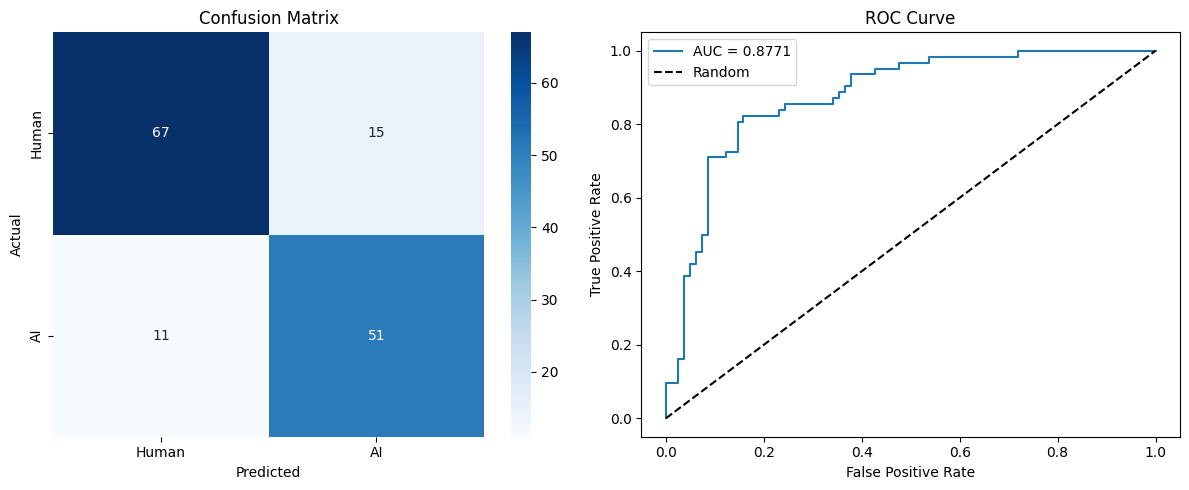

In [84]:
all_preds = []
all_labels = []
all_probs = []

model.eval()
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = torch.sigmoid(model(images))
        preds = (outputs.cpu() > 0.5).int().squeeze()
        all_preds.extend(preds.numpy())
        all_labels.extend(labels.numpy())
        all_probs.extend(outputs.cpu().squeeze().numpy())

# Metrics
accuracy = accuracy_score(all_labels, all_preds)
roc_auc = roc_auc_score(all_labels, all_probs)

print(f"Accuracy:  {accuracy:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")
print()
print(classification_report(all_labels, all_preds, target_names=['Human', 'AI']))

# Plot
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Confusion matrix
cm = confusion_matrix(all_labels, all_preds)
sns.heatmap(cm, annot=True, fmt='d', ax=axes[0],
            xticklabels=['Human', 'AI'],
            yticklabels=['Human', 'AI'],
            cmap='Blues')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')
axes[0].set_title('Confusion Matrix')

# ROC curve
fpr, tpr, _ = roc_curve(all_labels, all_probs)
axes[1].plot(fpr, tpr, label=f'AUC = {roc_auc:.4f}')
axes[1].plot([0, 1], [0, 1], 'k--', label='Random')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve')
axes[1].legend()

plt.tight_layout()
plt.show()

In [85]:
for threshold in [0.3, 0.4, 0.5, 0.6, 0.7]:
    preds = (torch.tensor(all_probs) > threshold).int().numpy()
    f1 = f1_score(all_labels, preds)
    acc = accuracy_score(all_labels, preds)
    print(f"Treshold {threshold}: Accuracy={acc:.3f}, F1={f1:.3f}")

Terskel 0.3: Accuracy=0.750, F1=0.757
Terskel 0.4: Accuracy=0.764, F1=0.757
Terskel 0.5: Accuracy=0.819, F1=0.797
Terskel 0.6: Accuracy=0.826, F1=0.797
Terskel 0.7: Accuracy=0.799, F1=0.756


### Analysis of Results

**Confusion Matrix**

The confusion matrix shows the breakdown of correct and incorrect predictions on the test set. The diagonal values represent correct classifications — true negatives (human correctly identified as human) and true positives (AI correctly identified as AI). Off-diagonal values represent misclassifications. A higher number of false positives than false negatives indicates the model is slightly more likely to label a human image as AI than the reverse, which aligns with the class imbalance in the original dataset.

**ROC Curve and AUC**

The ROC curve plots the true positive rate against the false positive rate across all possible classification thresholds. An AUC of 0.87 indicates the model correctly ranks a randomly chosen AI image above a randomly chosen human image 87% of the time. This is well above random chance (AUC = 0.5) and suggests the model has learned meaningful features that distinguish the two classes.

**Threshold Analysis**

The default threshold of 0.5 assumes equal confidence in both classes. Our treshhold analysis over different training sessions show that 0.5 - 0.6 is the most efficient treshold.

**Training Curves**

The loss curves show a consistent decrease in both training and validation loss during phase 1, confirming the model was learning. In phase 2, the gap between train and validation loss widened over time — a sign of overfitting. The best model checkpoint was saved at the epoch with the lowest validation loss to ensure we evaluate the most generalizable version of the model.

In [95]:
uploaded = files.upload()

Saving ChatGPT Image 28. apr. 2026, 09_25_13.png to ChatGPT Image 28. apr. 2026, 09_25_13 (2).png
Saving ChatGPT Image 30. apr. 2026, 12_29_59.png to ChatGPT Image 30. apr. 2026, 12_29_59.png
Saving Erling-Haaland-Wallpaper.jpg to Erling-Haaland-Wallpaper (1).jpg
Saving Mona lisa.webp to Mona lisa (1).webp
Saving ZQFWHxyt.jpg to ZQFWHxyt (1).jpg


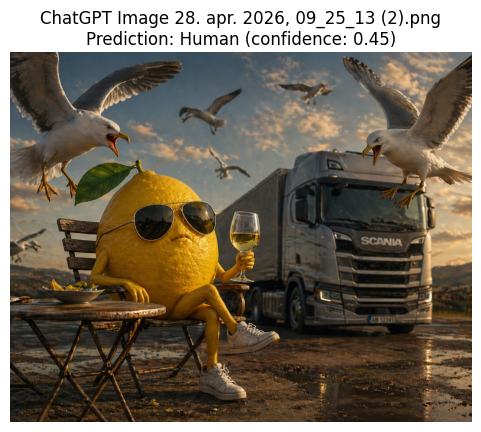

ChatGPT Image 28. apr. 2026, 09_25_13 (2).png: Human (sannsynlighet for AI: 0.45)


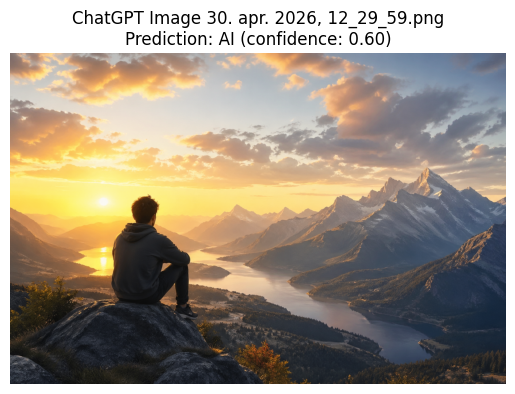

ChatGPT Image 30. apr. 2026, 12_29_59.png: AI (sannsynlighet for AI: 0.60)


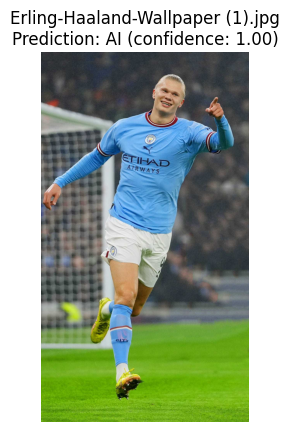

Erling-Haaland-Wallpaper (1).jpg: AI (sannsynlighet for AI: 1.00)


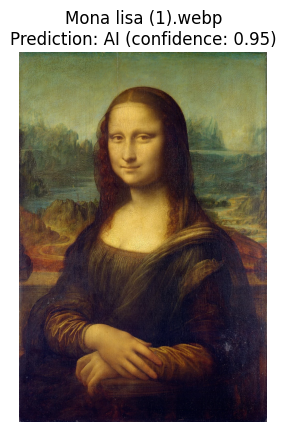

Mona lisa (1).webp: AI (sannsynlighet for AI: 0.95)


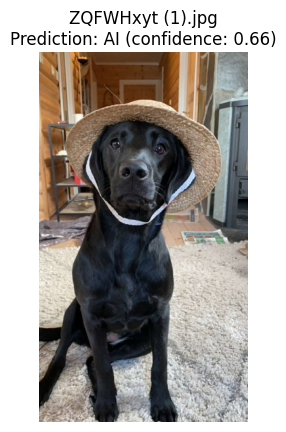

ZQFWHxyt (1).jpg: AI (sannsynlighet for AI: 0.66)


In [97]:
model.eval()

for filename, content in uploaded.items():

    img = Image.open(filename).convert('RGB')
    img_tensor = transform(img).unsqueeze(0).to(device)  # legg til batch dimensjon


    with torch.no_grad():
        output = torch.sigmoid(model(img_tensor))
        prob = output.item()
        pred = "AI" if prob > 0.5 else "Human"


    plt.imshow(img)
    plt.axis('off')
    plt.title(f"{filename}\nPrediction: {pred} (confidence: {prob:.2f})")
    plt.show()

    print(f"{filename}: {pred} (sannsynlighet for AI: {prob:.2f})")


####Promt for ai picture nr 1
lag ett bilde av en sitron som sitter å drikker ett glass vin, mens det er fugler som flyr rundt og vil spise sitronen. Inkluder også en stor lastebil i bakgrunnen (chatgpt 2026)

#### Promt for ai picture nr 2
create a picture that looks like it was made by ai (chatgpt)

####Erling haaland Picture
https://www.ixpap.com/erling-haaland-wallpaper/

#### Mona lisa
https://en.wikipedia.org/wiki/Mona_Lisa

#### Dog photo
It is privately acquired

## Conclusion

The goal of this project was to build a binary classifier distinguishing AI-generated images from human-made art using transfer learning on ResNet-18.

### Results Summary
The model achieved an accuracy of 0.82 and a ROC-AUC of 0.87 on the held-out test set. F1-scores were balanced between the two classes, suggesting the model does not strongly favor one class over the other. The WeightedRandomSampler helped compensate for the class imbalance of 526 AI vs 425 human images.

### Training Behaviour
Phase 1 training (head only) stabilized the classification head before fine-tuning. In Phase 2, unfreezing layer4 while keeping layer3 frozen provided a good balance between model flexibility and overfitting risk. Overfitting was observed from around epoch 9 onwards, where train loss continued to fall while validation loss plateaued. This was mitigated with dropout (0.5) and weight decay, though the gap between train and validation loss remained noticeable.

### Performance on Own Images
The model struggled on the 5 uploaded images, correctly classifying 1 out of 5. This suggests the model has limited generalization beyond its training distribution. Classical paintings such as the Mona Lisa, which is also part of the training data as a human photo, were misclassified as AI. This is a known limitation of small, domain-specific datasets.

### Limitations and Future Work
With only 951 images, the dataset is small for a task of this complexity. A larger and more diverse dataset would likely improve generalization significantly. The optimal model for this task would be a Vision Transformer (ViT) or a CLIP-based model, as these capture global image semantics more effectively than CNNs — precisely the properties where AI-generated images tend to fail. ResNet-18 was chosen as a practical compromise given hardware and time constraints.

Use of AI:
Deepseek (DeepSeek, 2026) and Claude (Anthropic, 2026) were used for assisting with debugging,
figures and tables. The AI tools helped with better understanding of the models that were used,
but the core model codes with parameters are original. The reflections of the analysis and comparison
are original.

In [107]:
import os
# Finn notebooken
for f in os.listdir('/content/drive/MyDrive/Colab Notebooks'):
    if f.endswith('.ipynb'):
        print(f)

Untitled0.ipynb
Resnet_18.ipynb
visualisere (1).ipynb
Untitled1.ipynb
Resnet_18(1).ipynb
Final_submition.ipynb
visualisere (2).ipynb


In [108]:
!jupyter nbconvert --to html "/content/drive/MyDrive/Colab Notebooks/Final_submition.ipynb"

[NbConvertApp] Converting notebook /content/drive/MyDrive/Colab Notebooks/Final_submition.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 12 image(s).
[NbConvertApp] Writing 3836394 bytes to /content/drive/MyDrive/Colab Notebooks/Final_submition.html


In [7]:
!apt-get install -y libatk1.0-0 libatk-bridge2.0-0 libcups2 libxkbcommon0 libxcomposite1 libxdamage1 libxfixes3 libxrandr2 libgbm1 libasound2
!playwright install chromium
!jupyter nbconvert --to webpdf --disable-chromium-sandbox "/content/drive/MyDrive/Colab Notebooks/Final_submition.ipynb"

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
libxdamage1 is already the newest version (1:1.1.5-2build2).
libxdamage1 set to manually installed.
libxfixes3 is already the newest version (1:6.0.0-1).
libxfixes3 set to manually installed.
libxkbcommon0 is already the newest version (1.4.0-1).
libxkbcommon0 set to manually installed.
libxrandr2 is already the newest version (2:1.5.2-1build1).
libxrandr2 set to manually installed.
libasound2 is already the newest version (1.2.6.1-1ubuntu1.1).
libasound2 set to manually installed.
libcups2 is already the newest version (2.4.1op1-1ubuntu4.16).
libcups2 set to manually installed.
libgbm1 is already the newest version (23.2.1-1ubuntu3.1~22.04.3).
libgbm1 set to manually installed.
The following additional packages will be installed:
  at-spi2-core gsettings-desktop-schemas libatk1.0-data libatspi2.0-0 libxtst6
  session-migration
The following NEW packages will be installed:
  at-spi2-core gs

In [ ]:
!pip install nbconvert[webpdf]
!jupyter nbconvert --to webpdf --allow-chromium-download "/content/drive/MyDrive/Colab Notebooks/Final_submition.ipynb"

from google.colab import files
files.download("/content/drive/MyDrive/Colab Notebooks/Final_submition.ipynb")